# English → Hindi Neural Machine Translation with BPCC–ILCI and OpenNMT-py

**Pipeline:** BPCC ILCI → verified English/Hindi columns → source-length-stratified train/validation/test split → SentencePiece → OpenNMT-py Transformer → SacreBLEU overall and by length bin.

> **Dataset access:** The BPCC dataset may require Hugging Face access approval and a token. This notebook does not invent BLEU results; run training and inference to obtain real scores. Default target is Hindi (`hin_Deva`). Edit `TARGET_LANG` if you want another ILCI language.

## 1. Install dependencies
Run this cell once. If package versions conflict with an existing runtime, use a fresh Python 3.10/3.11 environment.

In [ ]:
# %pip install -q "datasets>=2.18.0" "huggingface_hub>=0.23.0" pandas numpy scikit-learn sentencepiece sacrebleu matplotlib pyyaml
# %pip install -q OpenNMT-py

^C
Note: you may need to restart the kernel to use updated packages.


## 2. Configuration

In [ ]:
from pathlib import Path
import os, re, json, random, shutil, subprocess, sys, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Hindi is the default target language. The BPCC ILCI subset uses language identifiers.
SOURCE_LANG = "eng_Latn"
TARGET_LANG = "hin_Deva"  # e.g. Gujarati may be "guj_Gujr"; verify IDs in dataset

# Dataset configuration
DATASET_ID = "ai4bharat/BPCC"
DATASET_CONFIG = "ilci"  # if the Hub config name differs, inspect available configs in Section 3
MAX_SAMPLES = None       # set e.g. 20000 for a quick smoke test; None uses all available pairs
TEST_FRACTION = 0.10
VALID_FRACTION = 0.10   # fraction of the full dataset
MAX_SRC_TOKENS = 100
MAX_TGT_TOKENS = 100
WORKDIR = Path("bpcc_ilci_mt")
WORKDIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", WORKDIR.resolve())
print("Source:", SOURCE_LANG, "Target:", TARGET_LANG)

Working directory: C:\Users\Admin\OneDrive\Desktop\College Labs\ILLM\LAB 8\bpcc_ilci_mt
Source: eng_Latn Target: hin_Deva


## 3. Authenticate and load BPCC ILCI

If access is gated, create a Hugging Face read token and log in. The loader tries common dataset-loading patterns and prints a useful error rather than guessing column contents.

In [ ]:
from huggingface_hub import login, get_token
from datasets import load_dataset, get_dataset_config_names

HF_TOKEN = os.environ.get("HF_TOKEN") or get_token()
if not HF_TOKEN:
    try:
        from getpass import getpass
        HF_TOKEN = getpass("Hugging Face read token (input hidden; leave blank if already public): ").strip() or None
    except Exception:
        HF_TOKEN = None

if HF_TOKEN:
    login(token=HF_TOKEN, add_to_git_credential=False)

try:
    configs = get_dataset_config_names(DATASET_ID, token=HF_TOKEN)
    print("Available dataset configs (first 50):", configs[:50])
except Exception as e:
    configs = []
    print("Could not list configs:", repr(e))

ds = None
load_errors = []
config_candidates = []
for c in [DATASET_CONFIG, "ILCI", "ilci", None]:
    if c not in config_candidates:
        config_candidates.append(c)

for cfg in config_candidates:
    try:
        kwargs = {"token": HF_TOKEN}
        if cfg is not None:
            ds = load_dataset(DATASET_ID, cfg, **kwargs)
        else:
            ds = load_dataset(DATASET_ID, **kwargs)
        print("Loaded dataset with config:", cfg)
        break
    except Exception as e:
        load_errors.append((cfg, str(e)[:500]))

if ds is None:
    print("Dataset loading attempts:")
    for cfg, err in load_errors:
        print("  config =", cfg, "error =", err)
    raise RuntimeError(
        "Could not load BPCC. Confirm you have accepted the dataset access conditions, "
        "that the repository/config exists, and that your Hugging Face token has read access."
    )

print(ds)

Available dataset configs (first 50): ['bpcc-seed-latest', 'bpcc-seed-v2', 'bpcc-seed-v1', 'daily', 'comparable', 'ilci', 'nllb-seed', 'massive', 'nllb-filtered', 'samanantar-filtered', 'samanantar++']
Loaded dataset with config: ilci
DatasetDict({
    asm_Beng: Dataset({
        features: ['src_lang', 'tgt_lang', 'src', 'tgt'],
        num_rows: 82137
    })
    ben_Beng: Dataset({
        features: ['src_lang', 'tgt_lang', 'src', 'tgt'],
        num_rows: 123766
    })
    brx_Deva: Dataset({
        features: ['src_lang', 'tgt_lang', 'src', 'tgt'],
        num_rows: 83202
    })
    gom_Deva: Dataset({
        features: ['src_lang', 'tgt_lang', 'src', 'tgt'],
        num_rows: 74518
    })
    guj_Gujr: Dataset({
        features: ['src_lang', 'tgt_lang', 'src', 'tgt'],
        num_rows: 107385
    })
    hin_Deva: Dataset({
        features: ['src_lang', 'tgt_lang', 'src', 'tgt'],
        num_rows: 165649
    })
    kan_Knda: Dataset({
        features: ['src_lang', 'tgt_lang', 'sr

## 4. Select the ILCI English–Hindi pairs

**Important schema correction:** In your dataset preview, columns are `src_lang`, `tgt_lang`, `src`, `tgt`. The language identifiers are metadata; the actual sentences are columns **2 and 3** (zero-based). This cell filters English→Hindi by metadata where available and explicitly uses `src`/`tgt`, never the language-ID columns as text.

If the loaded dataset has multiple splits, they are combined and deduplicated. If the schema differs, the cell prints the schema and stops with a clear error.

In [ ]:
from datasets import Dataset, DatasetDict

# Convert each split to pandas and combine rows.
if isinstance(ds, DatasetDict):
    raw_parts = []
    for split_name, split_ds in ds.items():
        part = split_ds.to_pandas()
        part["_original_split"] = split_name
        raw_parts.append(part)
    raw = pd.concat(raw_parts, ignore_index=True)
else:
    raw = ds.to_pandas()

print("Columns:", list(raw.columns))
print("Shape:", raw.shape)
display(raw.head(5))

required = {"src", "tgt"}
if not required.issubset(raw.columns):
    raise ValueError(
        f"Expected sentence columns 'src' and 'tgt', found {list(raw.columns)}. "
        "Inspect the schema and adapt the column names; do not use src_lang/tgt_lang as sentences."
    )

# Filter the requested language direction using metadata if present.
if "src_lang" in raw.columns:
    raw = raw[raw["src_lang"].astype(str).str.strip().eq(SOURCE_LANG)]
if "tgt_lang" in raw.columns:
    raw = raw[raw["tgt_lang"].astype(str).str.strip().eq(TARGET_LANG)]

pairs = raw[["src", "tgt"]].copy()
pairs["src"] = pairs["src"].astype("string").str.strip()
pairs["tgt"] = pairs["tgt"].astype("string").str.strip()
pairs = pairs.dropna()
pairs = pairs[(pairs["src"].str.len() > 0) & (pairs["tgt"].str.len() > 0)]
pairs = pairs.drop_duplicates(subset=["src", "tgt"]).reset_index(drop=True)

# Filter rows that are likely language metadata / non-English sources.
latin_ratio = pairs["src"].map(lambda x: sum(ch.isascii() and ch.isalpha() for ch in x) / max(1, sum(ch.isalpha() for ch in x)))
pairs = pairs[latin_ratio >= 0.5].reset_index(drop=True)

if MAX_SAMPLES is not None and len(pairs) > MAX_SAMPLES:
    pairs = pairs.sample(n=MAX_SAMPLES, random_state=SEED).reset_index(drop=True)

print(f"English→{TARGET_LANG} pairs after filtering: {len(pairs):,}")
print("Unique English source sentences:", pairs["src"].nunique())
display(pairs.head(10))

if len(pairs) < 100:
    raise ValueError(
        "Fewer than 100 pairs were found. Check that TARGET_LANG matches the dataset's tgt_lang "
        "identifier and that src/tgt are the sentence columns. Inspect the rows above."
    )
if pairs["src"].nunique() < 100:
    raise ValueError("Source column still has fewer than 100 unique sentences; check dataset schema.")

Columns: ['src_lang', 'tgt_lang', 'src', 'tgt', '_original_split']
Shape: (1342628, 5)


,src_lang,tgt_lang,src,tgt,_original_split
0,eng_Latn,asm_Beng,What happened?,কি হ ` ল ?,asm_Beng
1,eng_Latn,asm_Beng,What’s the matter?,কি কথা ?,asm_Beng
2,eng_Latn,asm_Beng,One gets Moksha with a visit to the Saptapuris !,সপ্তপুৰীৰ দৰ্শনেৰে মুক্তি লাভ কৰিব পৰা যায় ।,asm_Beng
3,eng_Latn,asm_Beng,Pilgrimage is of utmost importance in Hinduism .,হিন্দু ধৰ্মত তীৰ্থৰ ডাঙৰ মহত্ব আছে ।,asm_Beng
4,eng_Latn,asm_Beng,Although all the pilgrimages are major and imp...,চাবলৈ গ'লে সকলোবোৰ তীৰ্থস্থানেই মহান আৰু সন্মা...,asm_Beng


English→hin_Deva pairs after filtering: 165,639
Unique English source sentences: 161452


,src,tgt
0,"Some countries have declining epidemics, with ...","कुछ देशों में महामारी घटती जा रही है, जहाँ कई ..."
1,Countries that have taken aggressive measures ...,जिन देशों ने वायरस को रोकने के लिए आक्रामक उपा...
2,We expect the number of cases and deaths to ri...,हम उम्मीद करते हैं कि आने वाले हफ्तों में मामल...
3,All countries must be ready to aggressively co...,सभी देशों को आक्रामक रूप से वायरस के लिए तैयार...
4,Transmission in most settings was driven by fa...,अधिकांश सेटिंग्स में प्रसार पारिवारिक समूहों द...
5,Approximately 80 per cent of cases are mild or...,"लगभग 80 फीसदी मामले हल्के या मध्यम होते हैं, 1..."
6,Virus shedding is highest early in the course ...,रोग की शुरुआत से पहले 24-48 घंटे तक वायरस शेडि...
7,Virus shedding usually continues for 7-12 days...,वायरस का निकलना आमतौर पर हल्के या मध्यम मामलों...
8,The WHO has consolidated its guidance for coun...,डब्लूएचओ ने देशों के लिए अपने मार्गदर्शन को चा...
9,"For the first three scenarios, health authorit...","पहले तीन परिदृश्यों में, स्वास्थ्य अधिकारी को ..."


## 5. Length bins and leakage-aware stratified split

Bins are based on **English source whitespace-token count**, as requested:
- Bin 1: length ≤ 10
- Bin 2: 10 < length < 20
- Bin 3: 20 ≤ length < 30
- Bin 4: length ≥ 30

To avoid source-sentence leakage, identical English sources are assigned to the same split. Stratification is done by source-length bin; rare bins are handled without forcing impossible train/validation/test allocations.

In [ ]:
def source_length(text):
    return len(str(text).split())

def length_bin(n):
    if n <= 10:
        return "Bin 1 (<=10)"
    elif n < 20:
        return "Bin 2 (11-19)"
    elif n < 30:
        return "Bin 3 (20-29)"
    return "Bin 4 (>=30)"

pairs["src_len"] = pairs["src"].map(source_length)
pairs["bin"] = pairs["src_len"].map(length_bin)

# Group by unique source to ensure all translations of the same source remain in one split.
groups = pairs.groupby("src", as_index=False).agg(
    bin=("bin", lambda x: x.mode().iloc[0]),
    src_len=("src_len", "first")
)
print("Unique-source distribution:")
display(groups["bin"].value_counts().reindex(
    ["Bin 1 (<=10)", "Bin 2 (11-19)", "Bin 3 (20-29)", "Bin 4 (>=30)"], fill_value=0
).rename("unique_sources").to_frame())

# Split each bin separately. If a bin has fewer than 3 unique sources, use best feasible split
# and warn; never throw away all usable data just because a bin is small.
train_sources, valid_sources, test_sources = set(), set(), set()
split_counts = []
for b in ["Bin 1 (<=10)", "Bin 2 (11-19)", "Bin 3 (20-29)", "Bin 4 (>=30)"]:
    subset = groups[groups["bin"] == b]["src"].tolist()
    rng = np.random.RandomState(SEED)
    rng.shuffle(subset)
    n = len(subset)
    if n == 0:
        split_counts.append({"bin": b, "unique_sources": 0, "train": 0, "valid": 0, "test": 0})
        continue
    if n == 1:
        tr, va, te = subset, [], []
        warnings.warn(f"{b} has only one unique source; it can only be assigned to train.")
    elif n == 2:
        tr, va, te = subset[:1], [], subset[1:]
        warnings.warn(f"{b} has only two unique sources; validation cannot be represented.")
    else:
        n_test = max(1, int(round(n * TEST_FRACTION)))
        n_valid = max(1, int(round(n * VALID_FRACTION)))
        # Ensure at least one train example remains.
        while n_test + n_valid >= n:
            if n_test >= n_valid and n_test > 1: n_test -= 1
            elif n_valid > 1: n_valid -= 1
            else: break
        te = subset[:n_test]
        va = subset[n_test:n_test+n_valid]
        tr = subset[n_test+n_valid:]
        if not tr:
            tr, va, te = subset[:-2], [subset[-2]], [subset[-1]]
    train_sources.update(tr); valid_sources.update(va); test_sources.update(te)
    split_counts.append({"bin": b, "unique_sources": n, "train": len(tr), "valid": len(va), "test": len(te)})

train_df = pairs[pairs["src"].isin(train_sources)].copy()
valid_df = pairs[pairs["src"].isin(valid_sources)].copy()
test_df = pairs[pairs["src"].isin(test_sources)].copy()

print("Split counts by bin:")
display(pd.DataFrame(split_counts))
print(f"Rows: train={len(train_df):,}, validation={len(valid_df):,}, test={len(test_df):,}")
print("Source overlap train/valid:", len(set(train_df.src) & set(valid_df.src)))
print("Source overlap train/test:", len(set(train_df.src) & set(test_df.src)))
print("Source overlap valid/test:", len(set(valid_df.src) & set(test_df.src)))

assert not (set(train_df.src) & set(valid_df.src))
assert not (set(train_df.src) & set(test_df.src))
assert not (set(valid_df.src) & set(test_df.src))

# Persist splits for reproducibility.
for name, frame in [("train", train_df), ("valid", valid_df), ("test", test_df)]:
    frame[["src", "tgt"]].to_csv(WORKDIR / f"{name}.tsv", sep="\t", index=False, header=False)

Unique-source distribution:


,unique_sources
bin,
Bin 1 (<=10),32496
Bin 2 (11-19),67546
Bin 3 (20-29),41831
Bin 4 (>=30),19579


Split counts by bin:


,bin,unique_sources,train,valid,test
0,Bin 1 (<=10),32496,25996,3250,3250
1,Bin 2 (11-19),67546,54036,6755,6755
2,Bin 3 (20-29),41831,33465,4183,4183
3,Bin 4 (>=30),19579,15663,1958,1958


Rows: train=132,528, validation=16,553, test=16,558
Source overlap train/valid: 0
Source overlap train/test: 0
Source overlap valid/test: 0


## 6. Inspect the length distribution

,train,validation,test
bin,,,
Bin 1 (<=10),26714,3333,3319
Bin 2 (11-19),55531,6935,6931
Bin 3 (20-29),34284,4291,4301
Bin 4 (>=30),15999,1994,2007


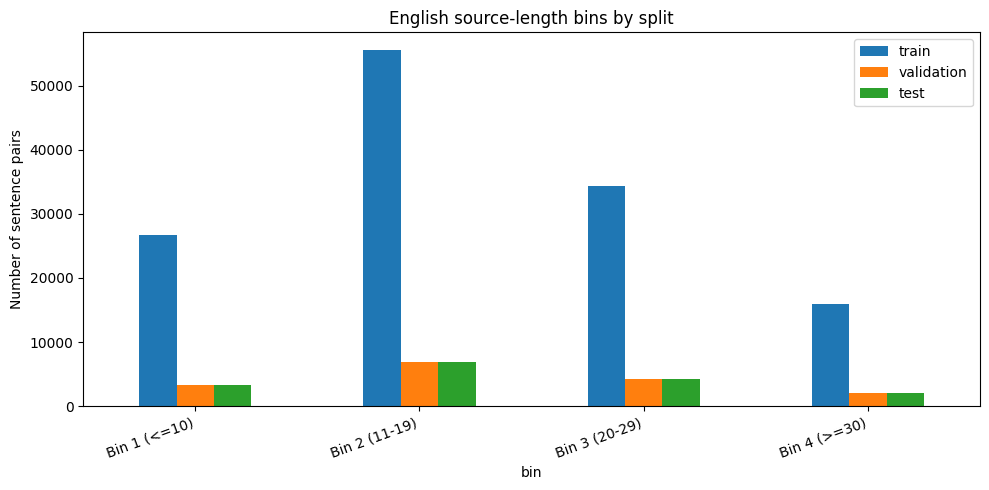

In [ ]:
order = ["Bin 1 (<=10)", "Bin 2 (11-19)", "Bin 3 (20-29)", "Bin 4 (>=30)"]
dist = pd.DataFrame({
    "train": train_df["bin"].value_counts().reindex(order, fill_value=0),
    "validation": valid_df["bin"].value_counts().reindex(order, fill_value=0),
    "test": test_df["bin"].value_counts().reindex(order, fill_value=0),
})
display(dist)
dist.plot(kind="bar", figsize=(10, 5))
plt.title("English source-length bins by split")
plt.ylabel("Number of sentence pairs")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 7. Prepare OpenNMT-py data

OpenNMT-py uses separate source and target text files plus a YAML configuration. SentencePiece models are trained on the training split only. We tokenize both languages into subword pieces, then train OpenNMT-py on the tokenized files.

In [ ]:
import sentencepiece as spm

DATA_DIR = WORKDIR / "onmt_data"
DATA_DIR.mkdir(exist_ok=True)

def write_column(frame, col, path):
    frame[col].astype(str).to_csv(path, index=False, header=False, sep="\n")

for split_name, frame in [("train", train_df), ("valid", valid_df), ("test", test_df)]:
    write_column(frame, "src", DATA_DIR / f"{split_name}.src")
    write_column(frame, "tgt", DATA_DIR / f"{split_name}.tgt")

# SentencePiece training corpora: separate source and target models.
spm.SentencePieceTrainer.train(
    input=str(DATA_DIR / "train.src"),
    model_prefix=str(DATA_DIR / "src_sp"),
    vocab_size=8000, model_type="unigram", character_coverage=0.9995,
    pad_id=0, unk_id=1, bos_id=2, eos_id=3
)
spm.SentencePieceTrainer.train(
    input=str(DATA_DIR / "train.tgt"),
    model_prefix=str(DATA_DIR / "tgt_sp"),
    vocab_size=8000, model_type="unigram", character_coverage=0.9995,
    pad_id=0, unk_id=1, bos_id=2, eos_id=3
)

src_sp = spm.SentencePieceProcessor(model_file=str(DATA_DIR / "src_sp.model"))
tgt_sp = spm.SentencePieceProcessor(model_file=str(DATA_DIR / "tgt_sp.model"))

def tokenize_file(input_path, output_path, sp):
    with open(input_path, encoding="utf-8") as fin, open(output_path, "w", encoding="utf-8") as fout:
        for line in fin:
            fout.write(" ".join(sp.encode(line.strip(), out_type=str)) + "\n")

for split_name in ["train", "valid", "test"]:
    tokenize_file(DATA_DIR / f"{split_name}.src", DATA_DIR / f"{split_name}.src.tok", src_sp)
    tokenize_file(DATA_DIR / f"{split_name}.tgt", DATA_DIR / f"{split_name}.tgt.tok", tgt_sp)

print("Prepared tokenized files in:", DATA_DIR.resolve())

Prepared tokenized files in: C:\Users\Admin\OneDrive\Desktop\College Labs\ILLM\LAB 8\bpcc_ilci_mt\onmt_data


## 8. Build OpenNMT-py vocabulary

We use the OpenNMT-py CLI for vocabulary building, training, and translation. If the installed version uses slightly different CLI flags, inspect `onmt_build_vocab -h` and `onmt_train -h` printed below.

In [ ]:
def run_cmd(args, check=True):
    print("\n$", " ".join(map(str, args)))
    result = subprocess.run(list(map(str, args)), text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    print(result.stdout if len(result.stdout) <= 30000 else result.stdout[-30000:])
    if check and result.returncode != 0:
        raise RuntimeError(f"Command failed with exit code {result.returncode}: {' '.join(map(str,args))}")
    return result

run_cmd([sys.executable, "-m", "onmt.bin.build_vocab", "-h"], check=False)
run_cmd([sys.executable, "-m", "onmt.bin.train", "-h"], check=False)


$ c:\Users\Admin\AppData\Local\Programs\Python\Python310\python.exe -m onmt.bin.build_vocab -h
usage: build_vocab.py [-h] [-config CONFIG] [-save_config SAVE_CONFIG] -data
                      DATA [-skip_empty_level {silent,warning,error}]
                      [-transforms {bart,clean,docify,inferfeats,fuzzymatch,inlinetags,insert_mask_before_placeholder,filtertoolong,prefix,suffix,normalize,switchout,tokendrop,tokenmask,terminology,sentencepiece,bpe,onmt_tokenize,uppercase} [{bart,clean,docify,inferfeats,fuzzymatch,inlinetags,insert_mask_before_placeholder,filtertoolong,prefix,suffix,normalize,switchout,tokendrop,tokenmask,terminology,sentencepiece,bpe,onmt_tokenize,uppercase} ...]]
                      -save_data SAVE_DATA [-overwrite] [-n_sample N_SAMPLE]
                      [-dump_samples] [-num_threads NUM_THREADS]
                      [-learn_subwords]
                      [-learn_subwords_size LEARN_SUBWORDS_SIZE]
                      [-vocab_sample_queue_size VOCAB_SA

CompletedProcess(args=['c:\\Users\\Admin\\AppData\\Local\\Programs\\Python\\Python310\\python.exe', '-m', 'onmt.bin.train', '-h'], returncode=0, stdout='usage: train.py [-h] [-config CONFIG] [-save_config SAVE_CONFIG] -data DATA\n                [-skip_empty_level {silent,warning,error}]\n                [-transforms {bart,clean,docify,inferfeats,fuzzymatch,inlinetags,insert_mask_before_placeholder,filtertoolong,prefix,suffix,normalize,switchout,tokendrop,tokenmask,terminology,sentencepiece,bpe,onmt_tokenize,uppercase} [{bart,clean,docify,inferfeats,fuzzymatch,inlinetags,insert_mask_before_placeholder,filtertoolong,prefix,suffix,normalize,switchout,tokendrop,tokenmask,terminology,sentencepiece,bpe,onmt_tokenize,uppercase} ...]]\n                [-save_data SAVE_DATA] [-overwrite] [-n_sample N_SAMPLE]\n                [-dump_transforms] -src_vocab SRC_VOCAB [-tgt_vocab TGT_VOCAB]\n                [-share_vocab] [--decoder_start_token DECODER_START_TOKEN]\n                [--default_spec

## 9. Create OpenNMT configuration and train Transformer

In [ ]:
from datetime import datetime
config_path = WORKDIR / "config.yaml"
model_dir = WORKDIR / "models"
model_dir.mkdir(exist_ok=True)
vocab_path = DATA_DIR / "vocab.txt"

config = {
    "save_data": str(DATA_DIR / "onmt"),
    "src_vocab": str(vocab_path),
    "tgt_vocab": str(vocab_path),
    "src_vocab_size": 8000,
    "tgt_vocab_size": 8000,
    "share_vocab": True,
    "src_seq_length": MAX_SRC_TOKENS,
    "tgt_seq_length": MAX_TGT_TOKENS,
    "data": {
        "corpus_1": {
            "path_src": str(DATA_DIR / "train.src.tok"),
            "path_tgt": str(DATA_DIR / "train.tgt.tok"),
            "transforms": [],
            "weight": 1
        },
        "valid": {
            "path_src": str(DATA_DIR / "valid.src.tok"),
            "path_tgt": str(DATA_DIR / "valid.tgt.tok"),
            "transforms": []
        }
    },
    "save_model": str(model_dir / "bpcc_transformer"),
    "save_checkpoint_steps": 2000,
    "keep_checkpoint": 3,
    "train_steps": 1000,
    "valid_steps": 1000,
    "warmup_steps": 40,
    "report_every": 10,
    "decoder_type": "transformer",
    "encoder_type": "transformer",
    "layers": 4,
    "hidden_size": 256,
    "word_vec_size": 256,
    "transformer_ff": 1024,
    "heads": 4,
    "dropout": 0.1,
    "position_encoding": True,
    "optim": "adam",
    "adam_beta1": 0.9,
    "adam_beta2": 0.998,
    "decay_method": "noam",
    "learning_rate": 2.0,
    "label_smoothing": 0.1,
    "batch_size": 4096,
    "batch_type": "tokens",
    "normalization": "tokens",
    "max_grad_norm": 0.0,
    "param_init": 0.0,
    "param_init_glorot": True,
    "valid_batch_size": 8,
    "early_stopping": 4,
    "seed": SEED,
    "world_size": 1,
    "gpu_ranks": [0] if __import__("torch").cuda.is_available() else [],
    "save_checkpoint_steps": 2000,
    "valid_steps": 1000,
    "log_file": str(WORKDIR / "train.log"),
    "log_file_level": "INFO"
}
config_path.write_text(__import__("yaml").safe_dump(config, sort_keys=False), encoding="utf-8")
print(config_path.read_text())

# Build vocabulary from the training data only.
# OpenNMT-py 3.x CLI entry points are generally available as onmt_build_vocab/onmt_train.
vocab_cmd = shutil.which("onmt_build_vocab")
train_cmd = shutil.which("onmt_train")
translate_cmd = shutil.which("onmt_translate")

if not vocab_cmd or not train_cmd or not translate_cmd:
    raise RuntimeError(
        "OpenNMT-py CLI executables were not found. Restart the kernel after installation, "
        "then rerun this cell. Check `!onmt_train -h`."
    )

# OpenNMT-py expects a positive sample count on many versions; use up to 100k
# training sentence pairs for vocabulary construction instead of -1.
n_vocab_samples = min(100000, len(train_df))
if n_vocab_samples < 1:
    raise ValueError("Training split is empty; inspect the dataset split in Section 5.")

# OpenNMT refuses to overwrite an existing vocabulary by default.
# Since the notebook may be rerun after a partial failure, remove the previous
# vocabulary files before rebuilding them.
for old_vocab in [vocab_path, DATA_DIR / "src_vocab.txt", DATA_DIR / "tgt_vocab.txt"]:
    if old_vocab.exists():
        old_vocab.unlink()

vocab_result = run_cmd(
    [vocab_cmd, "-config", config_path, "-n_sample", str(n_vocab_samples), "-overwrite"],
    check=False
)
if vocab_result.returncode != 0:
    print("\\nVocabulary build failed. The complete OpenNMT-py output is above.")
    print("Try running the command below in a notebook cell to see the full CLI diagnostic:")
    print(f'!onmt_build_vocab -config "{config_path}" -n_sample {n_vocab_samples}')
    raise RuntimeError(
        "OpenNMT vocabulary construction failed. Read the CLI output printed above; "
        "do not continue to training until it succeeds."
    )


# Reduce the training steps for a smoke test by setting TRAIN_STEPS before training if needed.
TRAIN_STEPS = 10000
config["train_steps"] = TRAIN_STEPS
config_path.write_text(__import__("yaml").safe_dump(config, sort_keys=False), encoding="utf-8")
# Timestamped live training log: prints wall-clock timestamps for every OpenNMT output line.
# This makes epoch/step progress and elapsed time visible while training is running.
def run_cmd_timestamped(args, log_path, check=True):
    args = list(map(str, args))
    print(f"[{datetime.now().astimezone().isoformat(timespec='seconds')}] START: {' '.join(args)}", flush=True)
    start = __import__("time").time()
    log_path = Path(log_path)
    log_path.parent.mkdir(parents=True, exist_ok=True)
    with open(log_path, "a", encoding="utf-8") as log:
        log.write(f"\\n[{datetime.now().astimezone().isoformat(timespec='seconds')}] START: {' '.join(args)}\\n")
        log.flush()
        proc = subprocess.Popen(
            args, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, encoding="utf-8", errors="replace", bufsize=1
        )
        try:
            for line in proc.stdout:
                stamp = datetime.now().astimezone().isoformat(timespec="seconds")
                message = f"[{stamp}] {line.rstrip()}"
                print(message, flush=True)
                log.write(message + "\\n")
                log.flush()
        except KeyboardInterrupt:
            proc.terminate()
            print(f"[{datetime.now().astimezone().isoformat(timespec='seconds')}] Interrupted; terminated training process.", flush=True)
            raise
        return_code = proc.wait()
    elapsed = __import__("time").time() - start
    print(f"[{datetime.now().astimezone().isoformat(timespec='seconds')}] END: exit={return_code}, elapsed={elapsed/60:.2f} min", flush=True)
    with open(log_path, "a", encoding="utf-8") as log:
        log.write(f"[{datetime.now().astimezone().isoformat(timespec='seconds')}] END: exit={return_code}, elapsed={elapsed/60:.2f} min\\n")
    if check and return_code != 0:
        raise RuntimeError(f"Timestamped training command failed with exit code {return_code}. See {log_path}")
    return return_code

training_log_path = WORKDIR / "training_timestamped.log"
run_cmd_timestamped([train_cmd, "-config", config_path], training_log_path)
print("Timestamped training log saved to:", training_log_path.resolve())

save_data: bpcc_ilci_mt\onmt_data\onmt
src_vocab: bpcc_ilci_mt\onmt_data\vocab.txt
tgt_vocab: bpcc_ilci_mt\onmt_data\vocab.txt
src_vocab_size: 8000
tgt_vocab_size: 8000
share_vocab: true
src_seq_length: 100
tgt_seq_length: 100
data:
  corpus_1:
    path_src: bpcc_ilci_mt\onmt_data\train.src.tok
    path_tgt: bpcc_ilci_mt\onmt_data\train.tgt.tok
    transforms: []
    weight: 1
  valid:
    path_src: bpcc_ilci_mt\onmt_data\valid.src.tok
    path_tgt: bpcc_ilci_mt\onmt_data\valid.tgt.tok
    transforms: []
save_model: bpcc_ilci_mt\models\bpcc_transformer
save_checkpoint_steps: 2000
keep_checkpoint: 3
train_steps: 1000
valid_steps: 1000
warmup_steps: 40
report_every: 10
decoder_type: transformer
encoder_type: transformer
layers: 4
hidden_size: 256
word_vec_size: 256
transformer_ff: 1024
heads: 4
dropout: 0.1
position_encoding: true
optim: adam
adam_beta1: 0.9
adam_beta2: 0.998
decay_method: noam
learning_rate: 2.0
label_smoothing: 0.1
batch_size: 4096
batch_type: tokens
normalization: tok

## 10. Translate the held-out test set

OpenNMT-py receives the same SentencePiece-tokenized English source used during preprocessing. The output is decoded with the target SentencePiece model before BLEU is computed.

In [ ]:
pred_tok_path = DATA_DIR / "test.pred.tok"
pred_path = DATA_DIR / "test.pred.txt"
model_path = model_dir / "bpcc_transformer_step_10000.pt"

# Select the latest checkpoint if training stopped at a different step.
checkpoints = sorted(model_dir.glob("bpcc_transformer_step_*.pt"), key=lambda p: p.stat().st_mtime)
if not checkpoints:
    raise FileNotFoundError(f"No OpenNMT checkpoint found in {model_dir}")
model_path = checkpoints[-1]
print("Using checkpoint:", model_path)

run_cmd([
    translate_cmd,
    "-model", model_path,
    "-src", DATA_DIR / "test.src.tok",
    "-output", pred_tok_path,
    "-verbose"
])

def decode_spm_file(input_path, output_path, sp):
    with open(input_path, encoding="utf-8") as fin, open(output_path, "w", encoding="utf-8") as fout:
        for line in fin:
            pieces = line.strip().split()
            fout.write(sp.decode(pieces) + "\n")

decode_spm_file(pred_tok_path, pred_path, tgt_sp)
predictions = pred_path.read_text(encoding="utf-8").splitlines()
references = test_df["tgt"].astype(str).tolist()
sources = test_df["src"].astype(str).tolist()

print("Predictions:", len(predictions), "References:", len(references))
display(pd.DataFrame({"English": sources[:10], "Reference Hindi": references[:10], "Predicted Hindi": predictions[:10]}))

## 11. Overall and bin-wise SacreBLEU

In [ ]:
import sacrebleu
from sacrebleu.metrics import BLEU

if len(predictions) != len(references):
    raise ValueError(f"Prediction/reference count mismatch: {len(predictions)} vs {len(references)}")

bleu = BLEU()
overall_score = bleu.corpus_score(predictions, [references])
print("Overall BLEU:", overall_score.score)
print(overall_score)

eval_df = test_df[["src", "tgt", "src_len", "bin"]].copy().reset_index(drop=True)
eval_df["prediction"] = predictions
rows = []
for b in order:
    subset = eval_df[eval_df["bin"] == b]
    if subset.empty:
        rows.append({"bin": b, "n": 0, "BLEU": np.nan, "note": "No test examples in this bin"})
        continue
    score = bleu.corpus_score(subset["prediction"].astype(str).tolist(),
                              [subset["tgt"].astype(str).tolist()])
    rows.append({"bin": b, "n": len(subset), "BLEU": score.score, "note": ""})

bleu_results = pd.DataFrame(rows)
display(bleu_results)

## 12. Bin-wise result analysis

The interpretation below is generated from your actual scores. BLEU is a corpus-level metric and may be noisy for small bins, so always report each bin's test count alongside the score.

In [ ]:
nonempty = bleu_results.dropna(subset=["BLEU"]).copy()
if nonempty.empty:
    print("No bin has test examples. Review the split counts in Section 5.")
else:
    best = nonempty.loc[nonempty["BLEU"].idxmax()]
    worst = nonempty.loc[nonempty["BLEU"].idxmin()]
    print(f"Highest BLEU: {best['bin']} = {best['BLEU']:.2f} (n={int(best['n'])})")
    print(f"Lowest BLEU:  {worst['bin']} = {worst['BLEU']:.2f} (n={int(worst['n'])})")
    for _, row in nonempty.iterrows():
        b, s, n = row["bin"], row["BLEU"], int(row["n"])
        if b.startswith("Bin 1"):
            comment = "Short sentences often have less context; a single token mismatch can strongly affect BLEU."
        elif b.startswith("Bin 2"):
            comment = "Short-to-medium sentences provide some context while remaining relatively easy to decode."
        elif b.startswith("Bin 3"):
            comment = "Longer structure can introduce reordering and agreement errors; inspect examples."
        else:
            comment = "Long sentences can be harder because of longer-range dependencies and compounding errors."
        print(f"- {b}: BLEU {s:.2f} over {n} examples. {comment}")
    bleu_results.dropna(subset=["BLEU"]).plot(x="bin", y="BLEU", kind="bar", legend=False, figsize=(9,4))
    plt.ylabel("SacreBLEU")
    plt.title("Bin-wise English→Hindi BLEU")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

print("\nReporting caveat: compare bins alongside sample counts. Do not claim a length trend from very small bins.")

## 13. Save results and sample translations

In [ ]:
results_path = WORKDIR / "binwise_bleu.csv"
bleu_results.to_csv(results_path, index=False)

summary = {
    "dataset": DATASET_ID,
    "subset": DATASET_CONFIG,
    "source_language": SOURCE_LANG,
    "target_language": TARGET_LANG,
    "train_pairs": int(len(train_df)),
    "validation_pairs": int(len(valid_df)),
    "test_pairs": int(len(test_df)),
    "overall_bleu": float(overall_score.score),
    "binwise_bleu": bleu_results.where(pd.notnull(bleu_results), None).to_dict(orient="records"),
    "sacrebleu_signature": str(overall_score)
}
summary_path = WORKDIR / "results_summary.json"
summary_path.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")

samples_path = WORKDIR / "translation_examples.csv"
eval_df[["src", "tgt", "prediction", "src_len", "bin"]].head(100).to_csv(samples_path, index=False)

print("Saved:")
print(" -", results_path.resolve())
print(" -", summary_path.resolve())
print(" -", samples_path.resolve())
display(bleu_results)

## 14. Report template

After the notebook completes, use the measured values in `binwise_bleu.csv` and `results_summary.json`.

**Suggested discussion:**
1. State overall SacreBLEU and test-set size.
2. Report the number of examples and BLEU score for each of the four bins.
3. Discuss whether BLEU decreases as English source length increases. Avoid asserting a monotonic trend unless the results support it.
4. Explain that longer sentences may require more reordering and long-range context, while short sentences may have unstable BLEU due to few tokens.
5. Mention limitations: dataset-domain mismatch, vocabulary/tokenization choices, training budget, and BLEU's limited ability to measure semantic adequacy.